# Droupout

Dropout is a technique used to prevent overfitting in neural networks, which consists of deactivating a set of neurons within the network's layers.

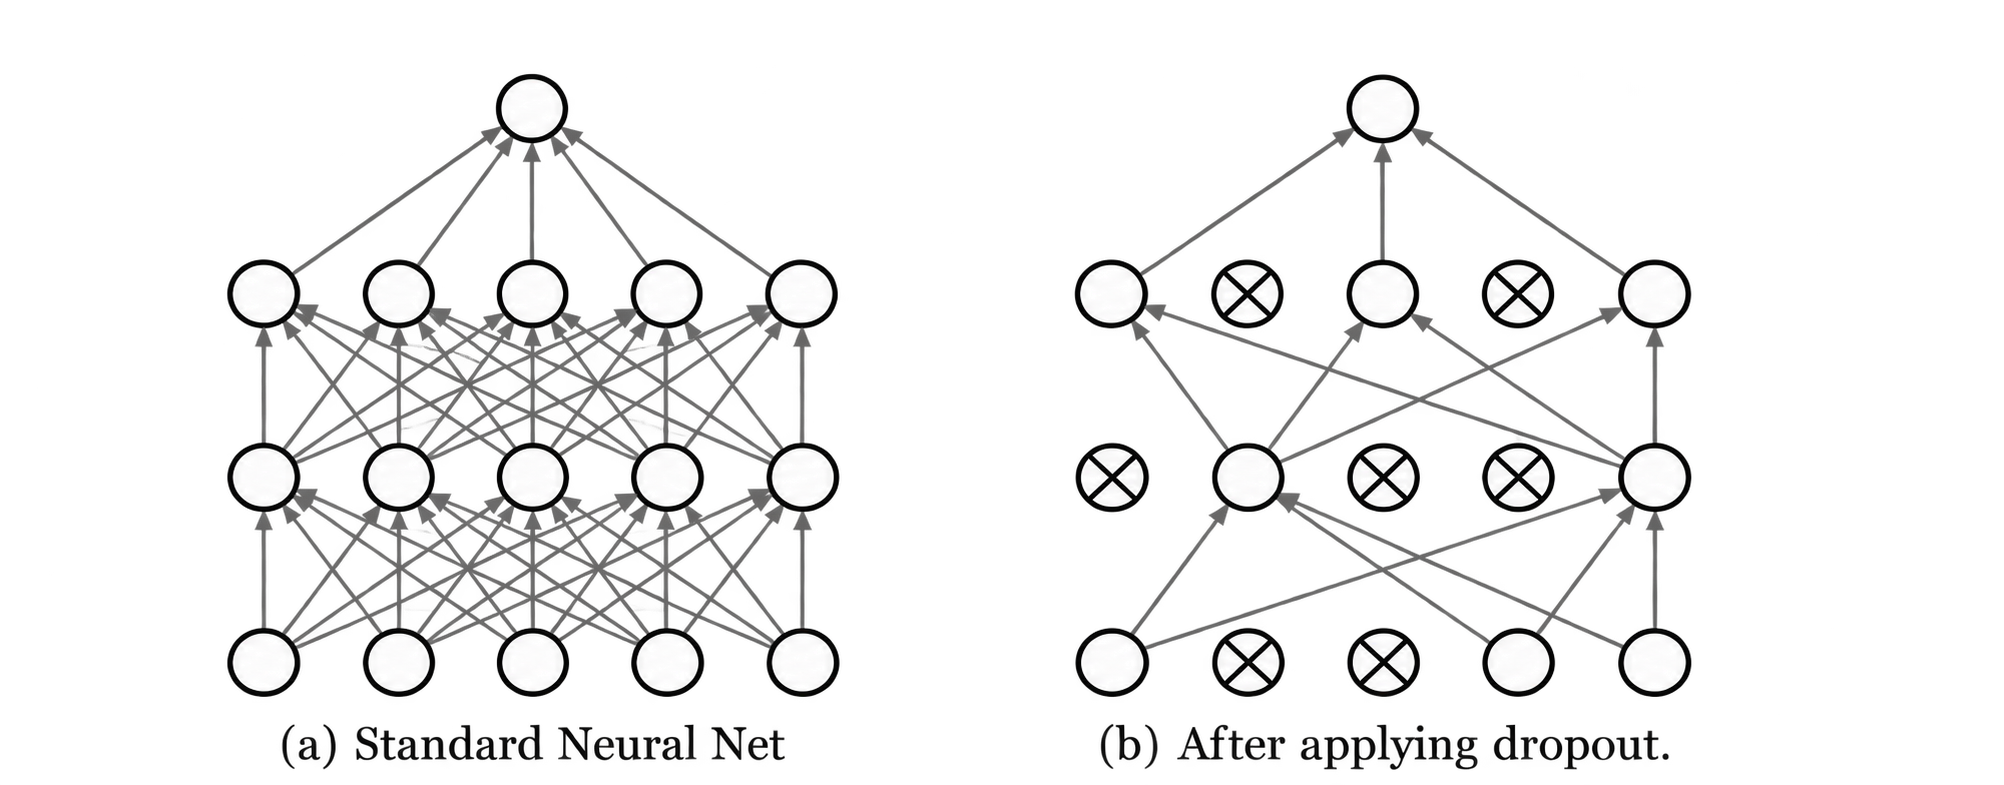

In accordance with the article (https://www.cs.toronto.edu/~rsalakhu/papers/srivastava14a.pdf), we select a percentage between 20% and 30%, which will correspond to the proportion of neurons in the chosen layer that we will deactivate.

In [1]:
import pandas as pd
import tensorflow as tf
import sklearn
import scikeras

from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import cross_val_score
from tensorflow.keras.models import Sequential
from tensorflow.keras import backend as k

from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt

## Data Loading

In [2]:
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 

X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# M = 1, B = 0
y = y["Diagnosis"].map({"B": 0, "M": 1}).to_frame()

## Neural Networ Structure Creating

In [3]:
def create_network():
    k.clear_session()
    neural_network = Sequential([
        tf.keras.layers.InputLayer(shape=(30,)),
        tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
        tf.keras.layers.Dropout(rate=0.2), # dropout 20%
        tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
        tf.keras.layers.Dropout(rate=0.2), # dropout 20%
        tf.keras.layers.Dense(units=1, activation='sigmoid')    
    ])
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001, clipvalue=0.5)
    neural_network.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['binary_accuracy'])
    return neural_network

In [4]:
neural_network = KerasClassifier(model=create_network, epochs=100, batch_size=10)

In [5]:
results = cross_val_score(estimator=neural_network, X=X, y=y, cv=10, scoring='accuracy')


Epoch 1/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - binary_accuracy: 0.5938 - loss: 1.1451
Epoch 2/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.7344 - loss: 0.6219
Epoch 3/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8555 - loss: 0.4108
Epoch 4/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8867 - loss: 0.3101
Epoch 5/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - binary_accuracy: 0.8984 - loss: 0.3091
Epoch 6/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8926 - loss: 0.3052
Epoch 7/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8848 - loss: 0.3106
Epoch 8/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8867 - loss: 0.3044
Epoch 9/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8906 - loss: 0.3100
Epoch 10/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8984 - loss: 0.2805
Epoch 11/100
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.8711 

In [7]:
results, results.mean(), results.std()

(array([0.77192982, 0.92982456, 0.92982456, 0.89473684, 0.92982456,
        0.92982456, 0.9122807 , 0.92982456, 0.92982456, 0.98214286]),
 np.float64(0.9140037593984962),
 np.float64(0.05167582538056853))

Dropout combats overfitting. If the network wasn't just memorizing the data (which is common given this number of neurons and an easy dataset), dropout might actually be counterproductive.